# Entregable 1 · Ingesta y transformación de datos con Spark

**Escenario.** Una operadora de telecomunicaciones recibe cada día un archivo con los registros de llamadas (*CDR, call detail records*): llamadas de voz, sesiones de datos y SMS, con la antena, la región y el estado de cada una. El objetivo es convertir ese archivo crudo en tablas fiables y en un resumen por región.

**Recorrido (arquitectura medallion):**

| Paso | Capa | Tabla |
|---|---|---|
| 1. Ingesta con esquema explícito | 🥉 Bronce | `bronce_llamadas` |
| 2. Perfilado de calidad | — | — |
| 3. Limpieza y columnas derivadas | 🥈 Plata | `plata_llamadas` |
| 4. Agregaciones y funciones de ventana | 🥇 Oro | `oro_llamadas_region`, `oro_antenas_top` |
| 5. Consulta en SQL sobre las tablas | — | — |

Todas las tablas son **Delta**. El cuaderno funciona igual en Databricks (Unity Catalog, cómputo sin servidor) y en local (Spark + Delta Lake). Solo cambia la celda de configuración.

*Datos: `telecom_cdrs.csv`, del repositorio de laboratorios DP-750 de Microsoft Learning (licencia MIT).*

In [1]:
import os

EN_DATABRICKS = 'DATABRICKS_RUNTIME_VERSION' in os.environ

if EN_DATABRICKS:
    # En Databricks: catálogo y esquema llegan como parámetros (widgets / parámetros del job)
    dbutils.widgets.text('catalogo', 'adb-dp750')
    dbutils.widgets.text('esquema', 'curso09')
    CATALOGO = dbutils.widgets.get('catalogo')
    ESQUEMA = dbutils.widgets.get('esquema')
    spark.sql(f'CREATE SCHEMA IF NOT EXISTS `{CATALOGO}`.{ESQUEMA}')
    spark.sql(f'CREATE VOLUME IF NOT EXISTS `{CATALOGO}`.{ESQUEMA}.datos_crudos')
    RUTA_DATOS = f'/Volumes/{CATALOGO}/{ESQUEMA}/datos_crudos'
    PREFIJO = f'`{CATALOGO}`.{ESQUEMA}'

    # Si el CSV aún no está en el volumen, se descarga del repositorio
    import urllib.request
    for archivo in ['telecom_cdrs.csv']:
        destino = f'{RUTA_DATOS}/{archivo}'
        if not os.path.exists(destino):
            urllib.request.urlretrieve('https://raw.githubusercontent.com/MiguelAP30/learning-data-science/main/cursos/09-databricks/datasets/' + archivo, destino)
else:
    # Fuera de Databricks: Spark + Delta Lake en local (ver entorno_local.py)
    from entorno_local import sesion_spark_local
    spark = sesion_spark_local('curso09-ingesta')
    ESQUEMA = 'curso09'
    spark.sql(f'CREATE DATABASE IF NOT EXISTS {ESQUEMA}')
    RUTA_DATOS = '../datasets'
    PREFIJO = ESQUEMA


def tabla(nombre):
    """Nombre completo de una tabla: catálogo.esquema.tabla en Databricks, esquema.tabla en local."""
    return f'{PREFIJO}.{nombre}'


print(f'Entorno: {"Databricks" if EN_DATABRICKS else "local"} · Spark {spark.version} · tablas en {PREFIJO}')

Entorno: local · Spark 4.0.1 · tablas en curso09


## 1. Ingesta (bronce)

El esquema se define a mano en vez de inferirse. Es más rápido (Spark no tiene que leer el archivo dos veces) y evita tipos equivocados: con inferencia, un teléfono como `+31612345001` podría leerse como número y perder el `+`. Las fechas se leen como texto a propósito: se convierten en la capa de plata, donde se controla qué pasa si alguna no es válida.

A cada fila se le añaden dos columnas de **metadatos de ingesta**: cuándo se cargó y de qué archivo vino. Son las que permiten rastrear un dato hasta su origen.

In [2]:
from pyspark.sql import functions as F, Window
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, DoubleType

esquema_cdr = StructType([
    StructField('call_id', StringType()),
    StructField('caller_msisdn', StringType()),
    StructField('callee_msisdn', StringType()),
    StructField('call_start_time', StringType()),
    StructField('call_end_time', StringType()),
    StructField('duration_seconds', IntegerType()),
    StructField('call_type', StringType()),
    StructField('call_status', StringType()),
    StructField('network_type', StringType()),
    StructField('cell_tower_id', StringType()),
    StructField('region', StringType()),
    StructField('roaming', StringType()),
    StructField('data_mb', DoubleType()),
    StructField('sms_count', IntegerType()),
])

bronce = (spark.read
          .option('header', True)
          .schema(esquema_cdr)
          .csv(f'{RUTA_DATOS}/telecom_cdrs.csv')
          .withColumn('_fecha_ingesta', F.current_timestamp())
          .withColumn('_archivo_origen', F.col('_metadata.file_name')))

bronce.write.format('delta').mode('overwrite').option('overwriteSchema', True).saveAsTable(tabla('bronce_llamadas'))
print(f"bronce_llamadas: {spark.table(tabla('bronce_llamadas')).count()} filas")
spark.table(tabla('bronce_llamadas')).printSchema()

bronce_llamadas: 30 filas
root
 |-- call_id: string (nullable = true)
 |-- caller_msisdn: string (nullable = true)
 |-- callee_msisdn: string (nullable = true)
 |-- call_start_time: string (nullable = true)
 |-- call_end_time: string (nullable = true)
 |-- duration_seconds: integer (nullable = true)
 |-- call_type: string (nullable = true)
 |-- call_status: string (nullable = true)
 |-- network_type: string (nullable = true)
 |-- cell_tower_id: string (nullable = true)
 |-- region: string (nullable = true)
 |-- roaming: string (nullable = true)
 |-- data_mb: double (nullable = true)
 |-- sms_count: integer (nullable = true)
 |-- _fecha_ingesta: timestamp (nullable = true)
 |-- _archivo_origen: string (nullable = true)



In [3]:
spark.table(tabla('bronce_llamadas')).select('call_id', 'call_start_time', 'call_end_time', 'duration_seconds',
                                              'call_type', 'call_status', 'region').show(5, truncate=False)

+-------+-------------------+-------------------+----------------+---------+-----------+---------+
|call_id|call_start_time    |call_end_time      |duration_seconds|call_type|call_status|region   |
+-------+-------------------+-------------------+----------------+---------+-----------+---------+
|CDR001 |2025-03-17 08:01:23|2025-03-17 08:04:47|204             |VOICE    |COMPLETED  |Amsterdam|
|CDR002 |2025-03-17 08:05:10|2025-03-17 08:05:10|0               |VOICE    |DROPPED    |Amsterdam|
|CDR003 |2025-03-17 08:10:00|2025-03-17 08:12:30|150             |VOICE    |COMPLETED  |Rotterdam|
|CDR004 |2025-03-17 08:15:45|2025-03-17 08:15:45|0               |VOICE    |NO_ANSWER  |Rotterdam|
|CDR005 |2025-03-17 08:20:00|2025-03-17 08:30:00|600             |DATA     |COMPLETED  |Eindhoven|
+-------+-------------------+-------------------+----------------+---------+-----------+---------+
only showing top 5 rows


## 2. Perfilado de calidad

Antes de transformar, se mide qué problemas tiene el archivo: nulos por columna e incoherencias entre columnas.

In [4]:
b = spark.table(tabla('bronce_llamadas'))
nulos = b.select([F.sum(F.col(c).isNull().cast('int')).alias(c) for c in esquema_cdr.fieldNames()])
print('Nulos por columna (solo las que tienen alguno):')
fila = nulos.first().asDict()
print({c: n for c, n in fila.items() if n})

inicio = F.to_timestamp('call_start_time', 'yyyy-MM-dd HH:mm:ss')
fin = F.to_timestamp('call_end_time', 'yyyy-MM-dd HH:mm:ss')
b.select(
    F.count('*').alias('filas'),
    F.sum((F.col('duration_seconds') < 0).cast('int')).alias('duracion_negativa'),
    F.sum((fin < inicio).cast('int')).alias('fin_antes_de_inicio'),
    F.sum(((fin.cast('long') - inicio.cast('long')) != F.col('duration_seconds')).cast('int')).alias('duracion_no_cuadra'),
    F.countDistinct('call_id').alias('ids_distintos'),
).show()

Nulos por columna (solo las que tienen alguno):


{'callee_msisdn': 1}


+-----+-----------------+-------------------+------------------+-------------+
|filas|duracion_negativa|fin_antes_de_inicio|duracion_no_cuadra|ids_distintos|
+-----+-----------------+-------------------+------------------+-------------+
|   30|                1|                  1|                 0|           30|
+-----+-----------------+-------------------+------------------+-------------+



**Hallazgos:**

- El único nulo es el destinatario de un SMS (`callee_msisdn`). No es un error, así que se conserva.
- Hay una llamada con **duración negativa** cuya hora de fin es anterior a la de inicio: un error del sistema de origen. No puede llegar a plata.
- En todas las demás filas, la duración declarada cuadra exactamente con la diferencia entre fin e inicio.
- No hay identificadores repetidos.

## 3. Limpieza y transformación (plata)

- Fechas de texto a `timestamp`, con `try_to_timestamp`: una fecha mal escrita da nulo en vez de romper el proceso.
- `roaming` de texto (`"true"`/`"false"`) a booleano.
- Columnas derivadas: fecha, hora, minutos y un **resultado** legible.
- Regla de validez: duración no negativa y fin posterior o igual al inicio. Las filas inválidas se cuentan y no pasan.

In [5]:
plata = (spark.table(tabla('bronce_llamadas'))
         .withColumn('inicio', F.expr("try_to_timestamp(call_start_time, 'yyyy-MM-dd HH:mm:ss')"))
         .withColumn('fin', F.expr("try_to_timestamp(call_end_time, 'yyyy-MM-dd HH:mm:ss')"))
         .withColumn('es_roaming', F.lower('roaming') == 'true')
         .withColumn('fecha', F.to_date('inicio'))
         .withColumn('hora', F.hour('inicio'))
         .withColumn('duracion_min', F.round(F.col('duration_seconds') / 60, 2))
         .withColumn('resultado', F.when(F.col('call_status') == 'COMPLETED', 'completada')
                                   .when(F.col('call_status') == 'DROPPED', 'caída')
                                   .otherwise('no establecida'))
         .withColumn('es_valida', (F.col('duration_seconds') >= 0) & (F.col('fin') >= F.col('inicio'))))

invalidas = plata.filter(~F.col('es_valida'))
print(f'Filas inválidas descartadas: {invalidas.count()}')
invalidas.select('call_id', 'inicio', 'fin', 'duration_seconds').show()

columnas_plata = ['call_id', 'caller_msisdn', 'callee_msisdn', 'inicio', 'fin', 'fecha', 'hora', 'duration_seconds',
                  'duracion_min', 'call_type', 'call_status', 'resultado', 'network_type', 'cell_tower_id', 'region',
                  'es_roaming', 'data_mb', 'sms_count', '_fecha_ingesta', '_archivo_origen']
(plata.filter('es_valida').select(columnas_plata)
      .write.format('delta').mode('overwrite').option('overwriteSchema', True).saveAsTable(tabla('plata_llamadas')))
print(f"plata_llamadas: {spark.table(tabla('plata_llamadas')).count()} filas")

Filas inválidas descartadas: 1


+-------+-------------------+-------------------+----------------+
|call_id|             inicio|                fin|duration_seconds|
+-------+-------------------+-------------------+----------------+
| CDR010|2025-03-17 08:45:00|2025-03-17 08:41:00|            -240|
+-------+-------------------+-------------------+----------------+



plata_llamadas: 29 filas


## 4. Agregaciones (oro)

**Resumen por región:** volumen, minutos de voz, tasa de llamadas no completadas, datos consumidos y uso de *roaming*.

In [6]:
p = spark.table(tabla('plata_llamadas'))
oro_region = (p.groupBy('region')
              .agg(F.count('*').alias('registros'),
                   F.sum(F.when(F.col('call_type') == 'VOICE', 1).otherwise(0)).alias('llamadas_voz'),
                   F.round(F.sum(F.when(F.col('call_type') == 'VOICE', F.col('duracion_min')).otherwise(0)), 1).alias('minutos_voz'),
                   F.round(F.avg((F.col('call_status') != 'COMPLETED').cast('int')) * 100, 1).alias('pct_no_completadas'),
                   F.round(F.sum('data_mb'), 1).alias('datos_mb'),
                   F.sum(F.col('es_roaming').cast('int')).alias('registros_roaming'))
              .orderBy(F.desc('registros')))
oro_region.write.format('delta').mode('overwrite').option('overwriteSchema', True).saveAsTable(tabla('oro_llamadas_region'))
spark.table(tabla('oro_llamadas_region')).show()

+---------+---------+------------+-----------+------------------+--------+-----------------+
|   region|registros|llamadas_voz|minutos_voz|pct_no_completadas|datos_mb|registros_roaming|
+---------+---------+------------+-----------+------------------+--------+-----------------+
|Amsterdam|       12|           8|       30.7|               8.3|  1442.9|                3|
|Rotterdam|        6|           5|        3.6|              50.0|   875.2|                1|
|Groningen|        4|           4|        4.3|              25.0|     0.0|                0|
|Eindhoven|        4|           0|        0.0|               0.0|   881.9|                0|
|  Utrecht|        3|           3|        6.5|              33.3|     0.0|                0|
+---------+---------+------------+-----------+------------------+--------+-----------------+



**Antena con más minutos de cada región**, con una función de ventana. `rank()` numera las antenas *dentro de cada región* (`partitionBy`) por minutos de mayor a menor, sin colapsar las filas como haría un `groupBy`.

In [7]:
minutos_antena = p.groupBy('region', 'cell_tower_id').agg(F.round(F.sum('duracion_min'), 1).alias('minutos'),
                                                         F.count('*').alias('registros'))
ventana = Window.partitionBy('region').orderBy(F.desc('minutos'))
oro_antenas = (minutos_antena.withColumn('puesto', F.rank().over(ventana))
               .filter('puesto = 1').drop('puesto').orderBy(F.desc('minutos')))
oro_antenas.write.format('delta').mode('overwrite').option('overwriteSchema', True).saveAsTable(tabla('oro_antenas_top'))
spark.table(tabla('oro_antenas_top')).show()

+---------+-------------+-------+---------+
|   region|cell_tower_id|minutos|registros|
+---------+-------------+-------+---------+
|Amsterdam|TOWER-AMS-001|   40.9|        4|
|Eindhoven|TOWER-EHV-001|   30.0|        2|
|Rotterdam|TOWER-RTD-002|   30.0|        2|
|  Utrecht|TOWER-UTR-001|    3.4|        2|
|Groningen|TOWER-GRN-001|    3.0|        2|
+---------+-------------+-------+---------+



## 5. Consulta en SQL

Las tablas Delta se consultan igual con SQL que con la API de DataFrames. En Databricks esta celda podría escribirse con el comando mágico `%sql`; aquí se usa `spark.sql()` para que funcione en ambos entornos.

In [8]:
spark.sql(f'''
    SELECT hora,
           COUNT(*)                                                    AS registros,
           ROUND(100 * AVG(CASE WHEN call_status <> 'COMPLETED' THEN 1 ELSE 0 END), 1) AS pct_no_completadas,
           ROUND(SUM(data_mb), 1)                                      AS datos_mb
    FROM {tabla('plata_llamadas')}
    GROUP BY hora
    ORDER BY hora
''').show()

+----+---------+------------------+--------+
|hora|registros|pct_no_completadas|datos_mb|
+----+---------+------------------+--------+
|   8|        9|              22.2|   667.5|
|   9|       10|              20.0|   531.0|
|  10|       10|              20.0|  2001.5|
+----+---------+------------------+--------+



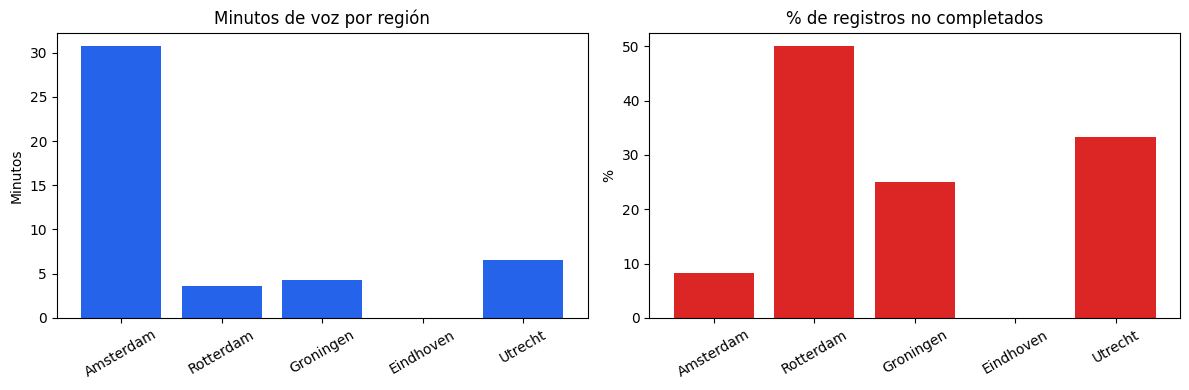

In [9]:
import matplotlib.pyplot as plt

resumen = spark.table(tabla('oro_llamadas_region')).toPandas()  # tabla de oro: pocas filas, seguro traerla al driver
fig, (izq, der) = plt.subplots(1, 2, figsize=(12, 4))
izq.bar(resumen['region'], resumen['minutos_voz'], color='#2563eb')
izq.set_title('Minutos de voz por región'); izq.set_ylabel('Minutos')
der.bar(resumen['region'], resumen['pct_no_completadas'], color='#dc2626')
der.set_title('% de registros no completados'); der.set_ylabel('%')
for eje in (izq, der):
    eje.tick_params(axis='x', rotation=30)
plt.tight_layout()
if not EN_DATABRICKS:
    plt.savefig('../imagenes/cdr-resumen-region.png', dpi=110, bbox_inches='tight')
plt.show()